# Notebook 05 — Item-Based Collaborative Filtering (MVP)

**Goal:** Build personalized retrieval with item co-occurrence, cosine and Jaccard, evaluate on the **same held-out positive pairs** as Notebook 04, and export candidate Parquet and metrics JSON.

**Design:** 30-day history strictly before each cutoff; binary user–item interactions; cap each user's recent history at 30 unique items for tractable co-occurrence; retain 50 neighbors per item; rank unseen items from each evaluation user's history. This is a **bounded-history approximation**, not full-catalog exact CF. No sampled negatives are used in retrieval evaluation. Empty recommendations are valid for cold-start users.

**Caution:** Popularity and CF use the same eligible historical item catalog, but CF may return fewer than 100 candidates for some users. We report that limitation rather than silently filling with popularity.

## 1. Environment
Run after Notebooks 02–04. The database file must be closed in other notebooks. Requires `duckdb pandas numpy pyarrow matplotlib`.

In [3]:
from pathlib import Path
import time, json
import duckdb, pandas as pd, numpy as np
from IPython.display import display
cwd=Path.cwd().resolve()
ROOT=next((p for p in (cwd,*cwd.parents) if (p/'data'/'processed'/'notebook02.duckdb').exists()),None)
if ROOT is None: raise FileNotFoundError('Run Notebook 02 first; missing notebook02.duckdb')
OUT=ROOT/'data'/'processed'; REPORT=ROOT/'data'/'reports'; REPORT.mkdir(exist_ok=True,parents=True)
con=duckdb.connect(str(OUT/'notebook02.duckdb'))
con.execute("SET memory_limit='4GB'"); con.execute('SET threads=4')
q=lambda p: "'"+p.as_posix().replace("'","''")+"'"
splits=('train','validation','test'); methods=('cooccurrence','cosine','jaccard')
existing={r[0] for r in con.execute('SHOW TABLES').fetchall()}
required={f'{s}_{suffix}' for s in splits for suffix in ('history','positives','pop_scores','enriched_examples')}
assert required.issubset(existing),f'Missing tables: {required-existing}. Run Notebook 04 first.'
for s in splits:
    print(s, 'history schema:',con.execute(f'DESCRIBE {s}_history').df()[['column_name','column_type']].to_dict('records'))
print('Root:',ROOT,'DuckDB:',duckdb.__version__)

train history schema: [{'column_name': 'user_id', 'column_type': 'BIGINT'}, {'column_name': 'item_id', 'column_type': 'BIGINT'}, {'column_name': 'n_events', 'column_type': 'BIGINT'}, {'column_name': 'last_ts', 'column_type': 'BIGINT'}]
validation history schema: [{'column_name': 'user_id', 'column_type': 'BIGINT'}, {'column_name': 'item_id', 'column_type': 'BIGINT'}, {'column_name': 'n_events', 'column_type': 'BIGINT'}, {'column_name': 'last_ts', 'column_type': 'BIGINT'}]
test history schema: [{'column_name': 'user_id', 'column_type': 'BIGINT'}, {'column_name': 'item_id', 'column_type': 'BIGINT'}, {'column_name': 'n_events', 'column_type': 'BIGINT'}, {'column_name': 'last_ts', 'column_type': 'BIGINT'}]
Root: C:\YR_Python_Code\multi-stage-ads-recommendation\notebooks DuckDB: 1.5.5


## 2. Build bounded binary user–item histories
Only history already produced by Notebook 02 is used. Use the most recent 30 distinct items per user to control the quadratic item-pair explosion. All events are strictly before the split cutoff. We derive recency from `events_raw` rather than assuming a timestamp column in the history table.

In [4]:
DAY=86_400_000
MAX_HISTORY_ITEMS=30
TOP_NEIGHBORS=50
TOP_K=100
MAX_PAIR_USERS=1000000  # safety guard: fail rather than silently sample users
build_stats=[]
for s in splits:
    cutoff=int(con.execute(f'SELECT MIN(cutoff_ts) FROM {s}_enriched_examples').fetchone()[0])
    assert con.execute(f'SELECT COUNT(DISTINCT cutoff_ts) FROM {s}_enriched_examples').fetchone()[0]==1
    start=cutoff-30*DAY
    t0=time.perf_counter()
    con.execute(f"""CREATE OR REPLACE TABLE {s}_cf_user_items AS
      WITH latest AS (
        SELECT user_id,item_id,MAX(ts) AS last_ts
        FROM events_raw WHERE ts >= {start} AND ts < {cutoff}
        GROUP BY user_id,item_id
      ), ranked AS (
        SELECT user_id,item_id,last_ts,
          ROW_NUMBER() OVER(PARTITION BY user_id ORDER BY last_ts DESC,item_id ASC) AS rn
        FROM latest
      ) SELECT user_id,item_id,last_ts FROM ranked WHERE rn <= {MAX_HISTORY_ITEMS}""")
    users,rows=con.execute(f'SELECT COUNT(DISTINCT user_id),COUNT(*) FROM {s}_cf_user_items').fetchone()
    if users>MAX_PAIR_USERS: raise RuntimeError('Too many users for this MVP; review memory budget')
    # Confirm selected items exist in Notebook 02 historical catalog
    invalid=con.execute(f"""SELECT COUNT(*) FROM {s}_cf_user_items h
      LEFT JOIN {s}_pop_scores p USING(item_id) WHERE p.item_id IS NULL""").fetchone()[0]
    assert invalid==0
    build_stats.append({'split':s,'stage':'history','users':int(users),'rows':int(rows),'seconds':time.perf_counter()-t0})
    print(s,'bounded history users:',users,'rows:',rows)

train bounded history users: 366673 rows: 517283
validation bounded history users: 336187 rows: 469133
test bounded history users: 300617 rows: 410239


## 3. Item–item similarities
For distinct users, `cooc(i,j)` counts users who interacted with both items. `cosine = cooc / sqrt(support_i × support_j)`; `jaccard = cooc / (support_i + support_j − cooc)`. Supports and co-occurrences use the **same capped histories**. Retain 50 neighbors per item, separately for each metric.

In [5]:
for s in splits:
    t0=time.perf_counter()
    con.execute(f"""CREATE OR REPLACE TABLE {s}_cf_support AS
      SELECT item_id,COUNT(*)::BIGINT AS support
      FROM {s}_cf_user_items GROUP BY item_id""")
    con.execute(f"""CREATE OR REPLACE TABLE {s}_cf_pairs AS
      SELECT a.item_id AS item_id,b.item_id AS neighbor_id,
        COUNT(*)::BIGINT AS cooc
      FROM {s}_cf_user_items a
      JOIN {s}_cf_user_items b
        ON a.user_id=b.user_id AND a.item_id<>b.item_id
      GROUP BY 1,2""")
    con.execute(f"""CREATE OR REPLACE TABLE {s}_cf_similarity AS
      SELECT p.item_id,p.neighbor_id,p.cooc,
        p.cooc::DOUBLE / SQRT(a.support::DOUBLE*b.support::DOUBLE) AS cosine,
        p.cooc::DOUBLE / (a.support+b.support-p.cooc) AS jaccard
      FROM {s}_cf_pairs p
      JOIN {s}_cf_support a ON p.item_id=a.item_id
      JOIN {s}_cf_support b ON p.neighbor_id=b.item_id""")
    for method in methods:
        score='cooc' if method=='cooccurrence' else method
        con.execute(f"""CREATE OR REPLACE TABLE {s}_cf_neighbors_{method} AS
          SELECT item_id,neighbor_id,{score}::DOUBLE AS similarity_score
          FROM {s}_cf_similarity
          QUALIFY ROW_NUMBER() OVER(PARTITION BY item_id
            ORDER BY {score} DESC,neighbor_id ASC) <= {TOP_NEIGHBORS}""")
    n_pairs=con.execute(f'SELECT COUNT(*) FROM {s}_cf_pairs').fetchone()[0]
    build_stats.append({'split':s,'stage':'similarity','directed_pairs':int(n_pairs),'seconds':time.perf_counter()-t0})
    print(s,'directed pairs:',n_pairs,'build seconds:',round(time.perf_counter()-t0,2))

train directed pairs: 956696 build seconds: 0.69
validation directed pairs: 822506 build seconds: 0.69
test directed pairs: 661082 build seconds: 0.82


## 4. Generate personalized candidates
For each evaluation user, sum neighbor similarity scores from their most recent historical items. Remove all items in their **full 30-day history**, not only the 30 capped seeds. Keep the Top-100 per user; users without connected neighbors may have fewer or zero results. Note: this measures batch generation, not API p95.

In [6]:
runs=[]
for s in splits:
    n_users=con.execute(f'SELECT COUNT(DISTINCT user_id) FROM {s}_positives').fetchone()[0]
    for method in methods:
        t0=time.perf_counter()
        table=f'{s}_cf_{method}_candidates'
        con.execute(f"""CREATE OR REPLACE TABLE {table} AS
          WITH seeds AS (
            SELECT h.user_id,h.item_id,h.last_ts
            FROM {s}_cf_user_items h
            JOIN (SELECT DISTINCT user_id FROM {s}_positives) u USING(user_id)
          ), scores AS (
            SELECT h.user_id,n.neighbor_id AS item_id,
              SUM(n.similarity_score) AS retrieval_score
            FROM seeds h JOIN {s}_cf_neighbors_{method} n ON h.item_id=n.item_id
            GROUP BY 1,2
          ), unseen AS (
            SELECT a.* FROM scores a
            WHERE NOT EXISTS (
              SELECT 1 FROM {s}_history h
              WHERE h.user_id=a.user_id AND h.item_id=a.item_id
            )
          ), ranked AS (
            SELECT *,ROW_NUMBER() OVER(PARTITION BY user_id
              ORDER BY retrieval_score DESC,item_id ASC) AS retrieval_rank
            FROM unseen
          ) SELECT user_id,item_id,retrieval_score,retrieval_rank,
            'cf_{method}'::VARCHAR AS retrieval_source
          FROM ranked WHERE retrieval_rank <= {TOP_K}""")
        seconds=time.perf_counter()-t0
        rows,covered=con.execute(f'SELECT COUNT(*),COUNT(DISTINCT user_id) FROM {table}').fetchone()
        dup=con.execute(f"""SELECT COUNT(*)-COUNT(DISTINCT (user_id,item_id)) FROM {table}""").fetchone()[0]
        seen=con.execute(f"""SELECT COUNT(*) FROM {table} c JOIN {s}_history h
           ON c.user_id=h.user_id AND c.item_id=h.item_id""").fetchone()[0]
        assert dup==0 and seen==0
        assert con.execute(f"""SELECT COUNT(*) FROM (
          SELECT user_id,MIN(retrieval_rank) AS lo,MAX(retrieval_rank) AS hi,COUNT(*) AS n
          FROM {table} GROUP BY user_id) WHERE lo<>1 OR hi<>n OR n>{TOP_K}""").fetchone()[0]==0
        result={'split':s,'method':method,'table':table,'evaluation_users':int(n_users),
                'covered_users':int(covered),'user_coverage':covered/n_users if n_users else None,
                'candidate_rows':int(rows),'build_seconds':seconds,
                'build_ms_per_user_amortized':1000*seconds/n_users if n_users else None}
        runs.append(result); print(result)
display(pd.DataFrame(runs))

{'split': 'train', 'method': 'cooccurrence', 'table': 'train_cf_cooccurrence_candidates', 'evaluation_users': 4110, 'covered_users': 3417, 'user_coverage': 0.8313868613138686, 'candidate_rows': 150451, 'build_seconds': 0.1566277000001719, 'build_ms_per_user_amortized': 0.03810892944043112}
{'split': 'train', 'method': 'cosine', 'table': 'train_cf_cosine_candidates', 'evaluation_users': 4110, 'covered_users': 3417, 'user_coverage': 0.8313868613138686, 'candidate_rows': 151096, 'build_seconds': 0.1128169000003254, 'build_ms_per_user_amortized': 0.027449367396672846}
{'split': 'train', 'method': 'jaccard', 'table': 'train_cf_jaccard_candidates', 'evaluation_users': 4110, 'covered_users': 3417, 'user_coverage': 0.8313868613138686, 'candidate_rows': 150764, 'build_seconds': 0.1194364000002679, 'build_ms_per_user_amortized': 0.029059951338264695}
{'split': 'validation', 'method': 'cooccurrence', 'table': 'validation_cf_cooccurrence_candidates', 'evaluation_users': 3657, 'covered_users': 2921

,split,method,table,evaluation_users,covered_users,user_coverage,candidate_rows,build_seconds,build_ms_per_user_amortized
0,train,cooccurrence,train_cf_cooccurrence_candidates,4110,3417,0.831387,150451,0.156628,0.038109
1,train,cosine,train_cf_cosine_candidates,4110,3417,0.831387,151096,0.112817,0.027449
2,train,jaccard,train_cf_jaccard_candidates,4110,3417,0.831387,150764,0.119436,0.029060
3,validation,cooccurrence,validation_cf_cooccurrence_candidates,3657,2921,0.798742,123940,0.093887,0.025673
4,validation,cosine,validation_cf_cosine_candidates,3657,2921,0.798742,124363,0.099602,0.027236
5,validation,jaccard,validation_cf_jaccard_candidates,3657,2921,0.798742,124080,0.113522,0.031042
6,test,cooccurrence,test_cf_cooccurrence_candidates,3572,2830,0.792273,114824,0.079926,0.022376
7,test,cosine,test_cf_cosine_candidates,3572,2830,0.792273,115178,0.085053,0.023811
8,test,jaccard,test_cf_jaccard_candidates,3572,2830,0.792273,114966,0.070930,0.019857


## 5. Evaluate exactly like Notebook 04
The denominator is the capped eligible future positive pairs in `{split}_positives`. Recall@K is micro pair recall; HitRate@K is fraction of **all evaluation users** with ≥1 retrieved positive. Macro recall includes zero-hit users. Coverage denominator is Notebook 04's historical eligible item catalog.

In [7]:
def evaluate(split,method,ks=(20,50,100)):
    table=f'{split}_cf_{method}_candidates'
    positives,users=con.execute(f'SELECT COUNT(*),COUNT(DISTINCT user_id) FROM {split}_positives').fetchone()
    catalog=con.execute(f'SELECT COUNT(*) FROM {split}_pop_scores').fetchone()[0]
    output=[]
    for k in ks:
        hits,hit_users=con.execute(f"""SELECT COUNT(*),COUNT(DISTINCT c.user_id)
          FROM {table} c JOIN {split}_positives p
            ON c.user_id=p.user_id AND c.item_id=p.item_id
          WHERE c.retrieval_rank<={int(k)}""").fetchone()
        macro=con.execute(f"""WITH pos AS (
           SELECT user_id,COUNT(*) AS n FROM {split}_positives GROUP BY 1
         ), hits AS (
           SELECT c.user_id,COUNT(*) AS n FROM {table} c
           JOIN {split}_positives p ON c.user_id=p.user_id AND c.item_id=p.item_id
           WHERE c.retrieval_rank<={int(k)} GROUP BY 1
         ) SELECT AVG(COALESCE(h.n,0)::DOUBLE/p.n)
         FROM pos p LEFT JOIN hits h USING(user_id)""").fetchone()[0]
        unique=con.execute(f'SELECT COUNT(DISTINCT item_id) FROM {table} WHERE retrieval_rank<={int(k)}').fetchone()[0]
        output.append({'split':split,'method':method,'k':int(k),'eligible_positive_pairs':int(positives),
           'users':int(users),'hits':int(hits),'recall_micro':hits/positives if positives else None,
           'recall_macro_user':float(macro) if macro is not None else None,
           'hit_rate':hit_users/users if users else None,'unique_recommended_items':int(unique),
           'catalog_coverage':unique/catalog if catalog else None})
    return output
metrics=[m for s in splits for method in methods for m in evaluate(s,method)]
metrics_df=pd.DataFrame(metrics)
display(metrics_df[metrics_df.split=='validation'].round(5))

,split,method,k,eligible_positive_pairs,users,hits,recall_micro,recall_macro_user,hit_rate,unique_recommended_items,catalog_coverage
9,validation,cooccurrence,20,9020,3657,510,0.05654,0.07218,0.10747,16297,0.13848
10,validation,cooccurrence,50,9020,3657,691,0.07661,0.08888,0.13016,23355,0.19845
11,validation,cooccurrence,100,9020,3657,788,0.08736,0.09562,0.13946,26633,0.22630
12,validation,cosine,20,9020,3657,377,0.04180,0.05391,0.08039,21611,0.18363
13,validation,cosine,50,9020,3657,577,0.06397,0.07770,0.11102,28369,0.24105
14,validation,cosine,100,9020,3657,692,0.07672,0.08718,0.12606,30784,0.26158
15,validation,jaccard,20,9020,3657,432,0.04789,0.06251,0.09215,21349,0.18140
16,validation,jaccard,50,9020,3657,632,0.07007,0.08425,0.11868,27965,0.23762
17,validation,jaccard,100,9020,3657,743,0.08237,0.09278,0.13344,30425,0.25852


## 6. Compare to Notebook 04 popularity
Use the prior report if available; do not tune based on Test. CF can outperform popularity on personalization and coverage even if its raw Recall@100 is lower.

,split,method,k,recall_micro,hit_rate,catalog_coverage
29,validation,cooccurrence,100,0.08736,0.13946,0.22630
35,validation,jaccard,100,0.08237,0.13344,0.25852
32,validation,cosine,100,0.07672,0.12606,0.26158
11,validation,decayed,100,0.03670,0.06262,0.00140
8,validation,global,100,0.03415,0.05934,0.00146


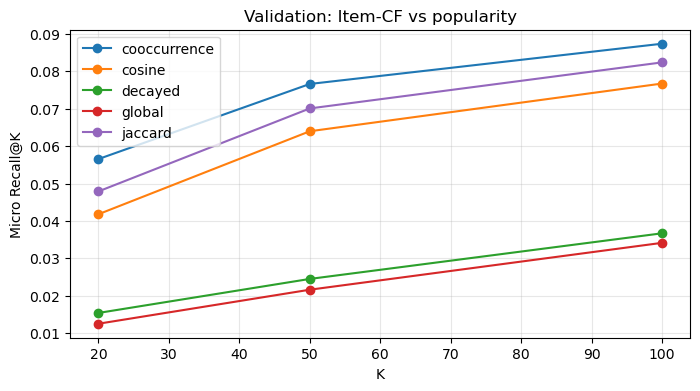

In [8]:
pop_report=REPORT/'notebook04_popularity_report.json'
if pop_report.exists():
    with pop_report.open('r',encoding='utf-8') as f: pop=json.load(f)
    pop_metrics=pd.DataFrame(pop['metrics'])
    compare=pd.concat([pop_metrics,metrics_df],ignore_index=True)
else:
    print('Notebook 04 JSON not found; displaying CF metrics only')
    compare=metrics_df.copy()
cols=['split','method','k','recall_micro','hit_rate','catalog_coverage']
display(compare[(compare.split=='validation') & (compare.k==100)][cols].sort_values('recall_micro',ascending=False).round(5))
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(8,4))
for method,g in compare[compare.split=='validation'].groupby('method'):
    ax.plot(g.k,g.recall_micro,marker='o',label=method)
ax.set(xlabel='K',ylabel='Micro Recall@K',title='Validation: Item-CF vs popularity')
ax.legend();ax.grid(alpha=.3);plt.show()

## 7. Export Parquet and JSON
Candidate files have the same five columns as Notebook 04 (`user_id,item_id,retrieval_score,retrieval_rank,retrieval_source`). Metrics CSV and JSON include all splits. Similarity neighbors are stored in DuckDB for reproducibility.

In [9]:
for s in splits:
    for method in methods:
        path=OUT/f'{s}_cf_{method}_top100.parquet'
        con.execute(f'COPY {s}_cf_{method}_candidates TO {q(path)} (FORMAT PARQUET)')
        assert path.exists() and path.stat().st_size>0, f'No candidate rows for {s}/{method}'
        print(path.name,round(path.stat().st_size/1024**2,2),'MiB')
metrics_df.to_csv(REPORT/'notebook05_retrieval_metrics.csv',index=False)
def safe(x):
    if isinstance(x,dict): return {str(k):safe(v) for k,v in x.items()}
    if isinstance(x,(list,tuple)):return [safe(v) for v in x]
    if isinstance(x,(np.integer,)):return int(x)
    if isinstance(x,(np.floating,)):return float(x) if np.isfinite(x) else None
    if isinstance(x,(np.bool_,)):return bool(x)
    return x
report={'notebook':'05_item_cf_retrieval','history_window_days':30,
        'max_history_items_per_user':MAX_HISTORY_ITEMS,'top_neighbors_per_item':TOP_NEIGHBORS,
        'max_k':TOP_K,'similarity_support':'binary distinct users in capped history',
        'runs':runs,'build_stats':build_stats,'metrics':metrics,
        'limitations':['Capped user histories approximate full item-item CF',
         'CF may return fewer than K items for some users; no popularity fallback added',
         'Evaluation positives are capped and eligible, not an unbiased full-future ground truth',
         'No impression logs; no real CTR or CVR claims',
         'Batch build time is not production request p95 latency']}
path=REPORT/'notebook05_item_cf_report.json'
with path.open('w',encoding='utf-8') as f:json.dump(safe(report),f,indent=2,allow_nan=False)
print('Saved:',path)

train_cf_cooccurrence_top100.parquet 0.73 MiB
train_cf_cosine_top100.parquet 1.13 MiB
train_cf_jaccard_top100.parquet 1.02 MiB
validation_cf_cooccurrence_top100.parquet 0.6 MiB
validation_cf_cosine_top100.parquet 0.9 MiB
validation_cf_jaccard_top100.parquet 0.82 MiB
test_cf_cooccurrence_top100.parquet 0.55 MiB
test_cf_cosine_top100.parquet 0.84 MiB
test_cf_jaccard_top100.parquet 0.76 MiB
Saved: C:\YR_Python_Code\multi-stage-ads-recommendation\notebooks\data\reports\notebook05_item_cf_report.json


## 8. Handoff
Upload `data/reports/notebook05_item_cf_report.json` for interpretation. Next Notebook 06: embedding-based retrieval. Later Notebook 08 will combine retrieval sources and evaluate fusion.

**Optimization follow-up:** investigate candidate user coverage, neighbor degree, capped-history sensitivity, sparse-matrix alternatives, and memory/latency trade-offs after the full MVP pipeline runs.